In [31]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
from typing import Any, Callable

# Reading Prices for Analysis

In [32]:
data = pd.read_excel("close_prices_portfolio.ods", engine="odf", index_col = 'Date', parse_dates = True)

data_log = pd.DataFrame(data.values, columns = data.columns, index = data.index)
data_log.index.name = "Date"
data_log[data_log.columns[:-1]] = np.log(data_log[data_log.columns[:-1]])
data_log['USD/EUR'] = np.exp(data_log['USD/EUR'])

In [33]:
data_log

,S&P 500,DAX,AEX,USD/EUR,S&P 500 in EUR,Euribor rates
Date,,,,,,
2012-04-10,7.214203,8.795799,5.723291,1.311131,7.485093,0.764
2012-04-11,7.221624,8.806084,5.729353,1.307360,7.489634,0.760
2012-04-12,7.235309,8.816296,5.739407,1.311992,7.506856,0.757
2012-04-13,7.222756,8.792383,5.723977,1.318913,7.499564,0.753
2012-04-16,7.222252,8.798634,5.723650,1.305653,7.488956,0.750
...,...,...,...,...,...,...
2022-04-04,8.430031,9.583156,6.603673,1.104728,8.529630,-0.547
2022-04-05,8.417399,9.576674,6.601257,1.097586,8.510513,-0.551
2022-04-06,8.407635,9.557589,6.578793,1.090643,8.494403,-0.548


### Loss Operator

In [34]:
def group4_loss_operator(log_data):
    rates = log_data['Euribor rates']
    rates_risk = 0.4 * (0.0002 + 0.25 * rates.diff().fillna(0))
    other_risk = 0.2 * log_data[['DAX','AEX','S&P 500 in EUR']].diff().fillna(0)
    ind_loss = pd.DataFrame(data = log_data[['S&P 500 in EUR', 'DAX', 'AEX', 'Euribor rates']].diff().fillna(0).values,
                             index = log_data.index, columns = ['S&P 500', 'DAX', 'AEX', 'EURIBOR'])
    ind_loss['EURIBOR'] = rates_risk
    return -1 * (other_risk.sum(axis = 1) + rates_risk), -1 * ind_loss

<Axes: xlabel='Date'>

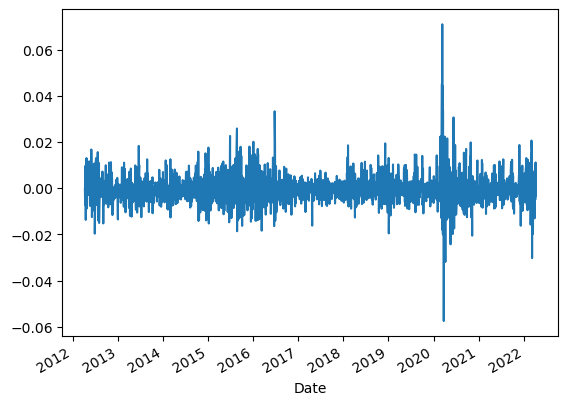

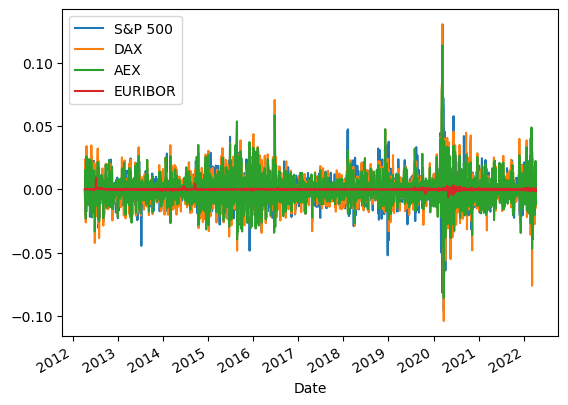

In [35]:
portfolio_loss, ind_loss = group4_loss_operator(log_data=data_log)
portfolio_loss.plot()
ind_loss.plot()

# Declaring methods to calculate VaR (LEGACY CODE)

In [36]:
window_size = 242 # days
weights = [.2, .2, .2, .4]

### VaR CoVar

In [37]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.ppf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError()

In [38]:
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

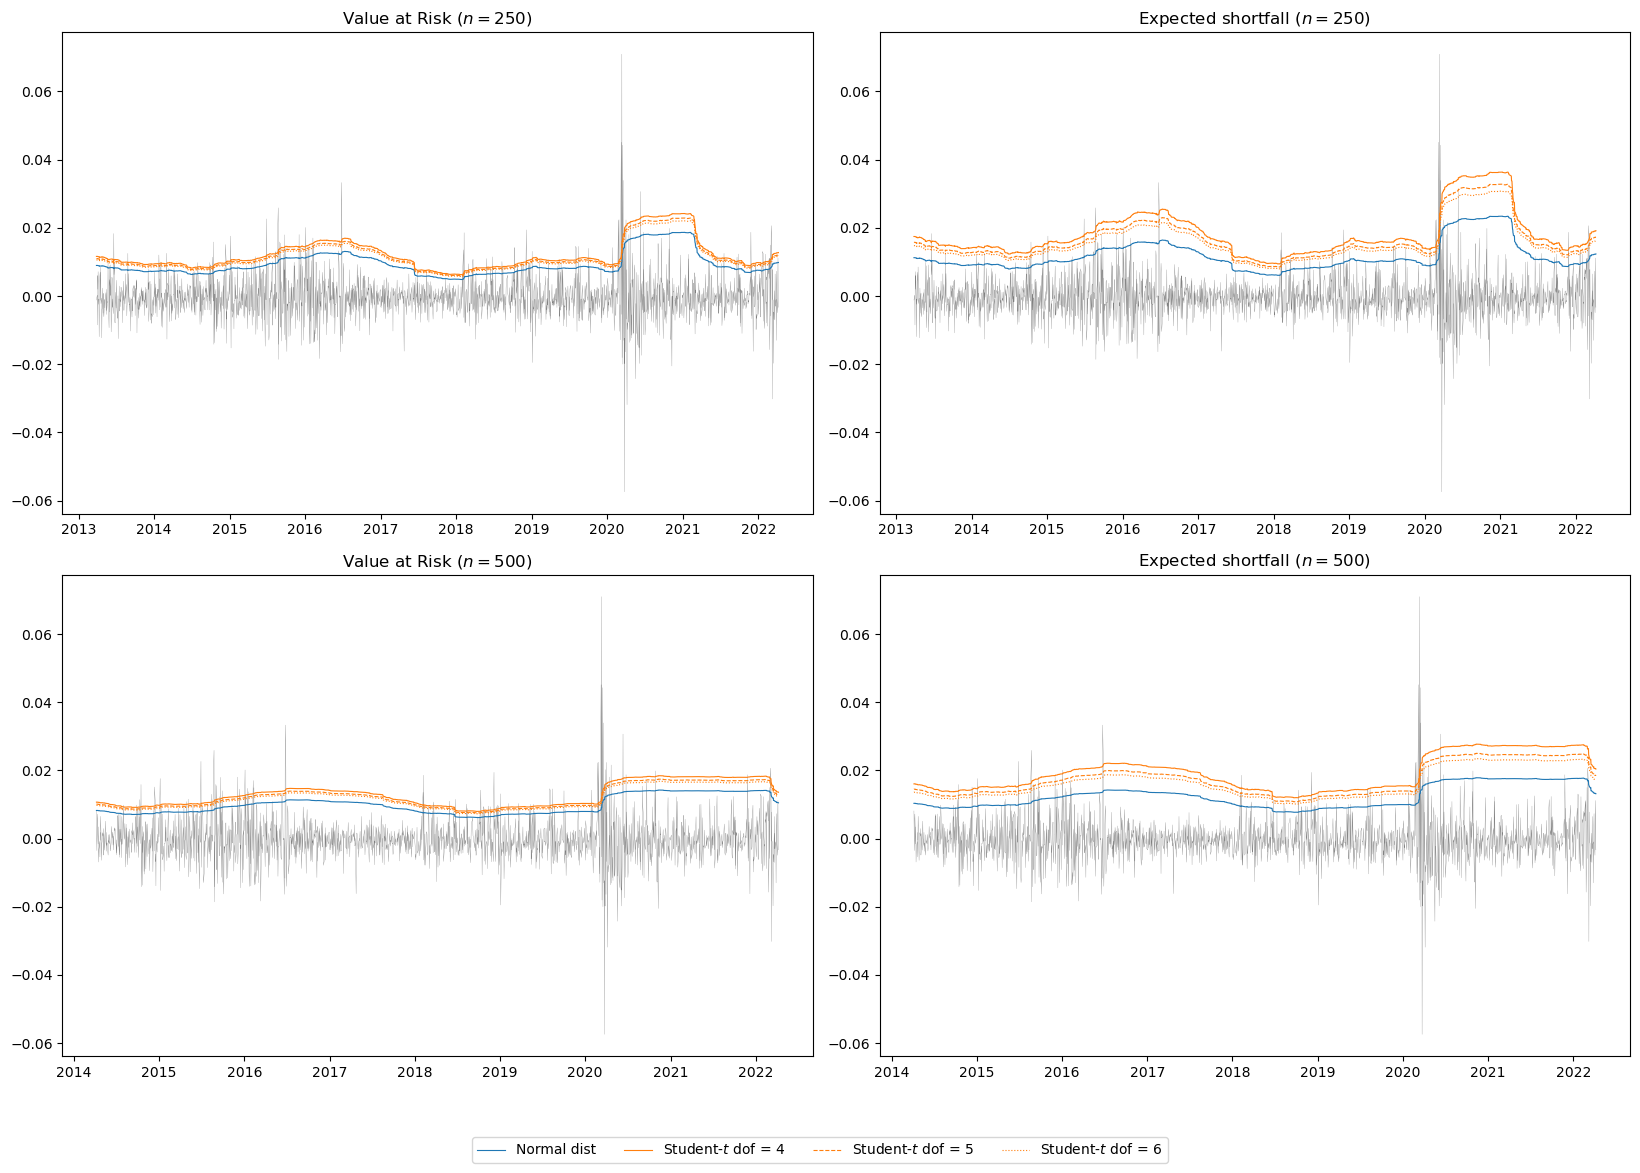

In [39]:
fig, axs = plt.subplots(2, 2, figsize = (16.5, 16.5 / 1.5)) #(8.2543, 8.2543 / 3)
axs[0,1].set_title('Expected shortfall $(n = 250)$')
axs[0,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[0,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0,0].set_title('Value at Risk $(n = 250)$')
axs[0,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[0,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)

window_size_long = 500 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size_long, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size_long, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size_long, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size_long, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size_long:]

axs[1,1].set_title('Expected shortfall $(n = 500)$')
axs[1,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[1,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[1,0].set_title('Value at Risk $(n = 500)$')
axs[1,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[1,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
fig.tight_layout()
plt.savefig('HS.pdf')
plt.show()

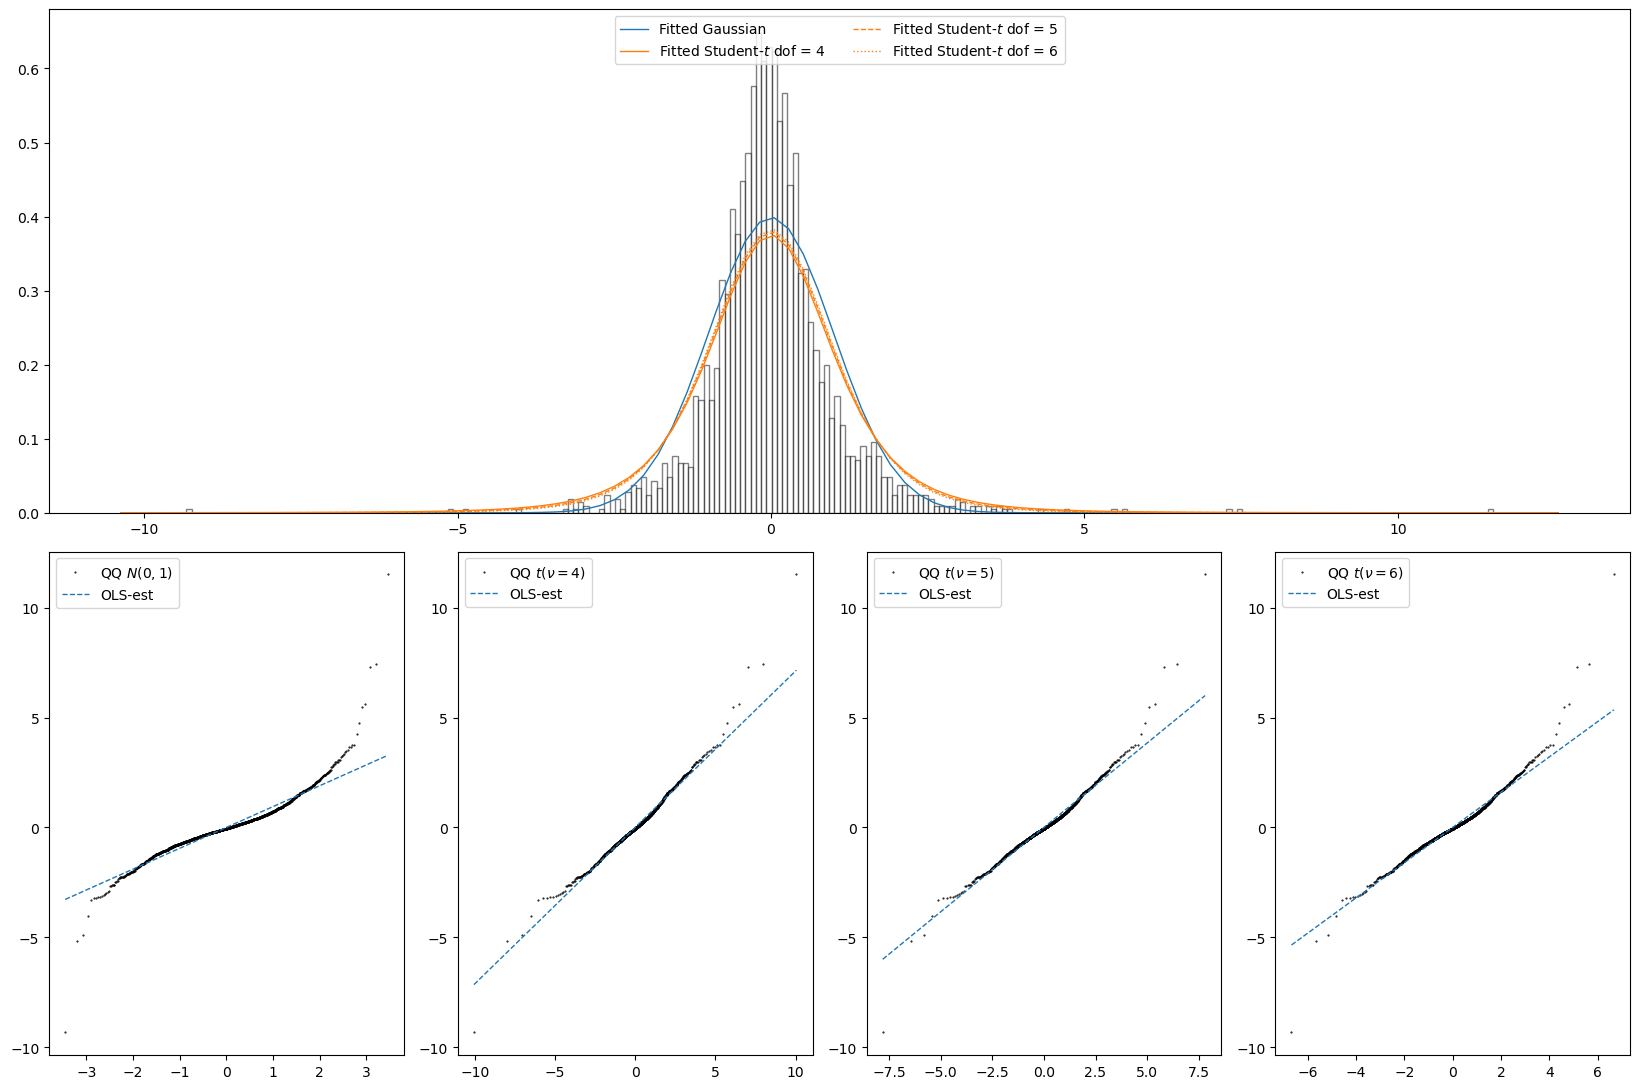

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import matplotlib as mpl

# Generate some random data
data = (ind_loss @ weights).dropna()
data = (data - data.mean()) / data.std()

# Create figure and subplots
# fig, axs = plt.subplots(2, 4, figsize=(12, 5))

# Plot histogram with density curve
fig = plt.figure(figsize = (16.5, 16.5 / 1.5))
gs = mpl.gridspec.GridSpec(2, 4)#, wspace=0.25, hspace=0.25) # 2x2 grid
axs = fig.add_subplot(gs[0, :]) # first row, first col
axs1 = fig.add_subplot(gs[1, 1]) # first row, second col
axs2 = fig.add_subplot(gs[1, 2])
axs3 = fig.add_subplot(gs[1, 3])
axs4 = fig.add_subplot(gs[1, 0])


axs.hist(data, bins=250, density=True, alpha=0.5, color='white', edgecolor='black')
xmin, xmax = axs.get_xlim()
x = np.linspace(xmin, xmax, 100)
pdf = stats.norm.pdf(x)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Gaussian')
pdf = stats.t.pdf(x, loc = np.mean(data), scale = np.std(data), df = 4)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Student-$t$ dof = 4', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs1, sparams = (4,))
axs1.get_lines()[1].set_color('C0')
axs1.get_lines()[1].set_linestyle('dashed')
axs1.get_lines()[1].set_linewidth(1)
axs1.get_lines()[0].set_marker('.')  # Set marker style to dots
axs1.get_lines()[0].set_color('black')  # Set marker color to black
axs1.get_lines()[0].set_markersize(1)  # Set marker size
# axs1.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 5)
axs.plot(x, pdf, linewidth=1, ls = 'dashed', label = 'Fitted Student-$t$ dof = 5', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs2, sparams = (5,))
axs2.get_lines()[1].set_color('C0')
axs2.get_lines()[1].set_linestyle('dashed')
axs2.get_lines()[1].set_linewidth(1)
axs2.get_lines()[0].set_marker('.')  # Set marker style to dots
axs2.get_lines()[0].set_color('black')  # Set marker color to black
axs2.get_lines()[0].set_markersize(1)  # Set marker size
# axs2.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 6)
axs.plot(x, pdf, linewidth=1, ls = 'dotted', label = 'Fitted Student-$t$ dof = 6', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs3, sparams = (6,))
axs3.get_lines()[1].set_color('C0')
axs3.get_lines()[1].set_linestyle('dashed')
axs3.get_lines()[1].set_linewidth(1)
axs3.get_lines()[0].set_marker('.')  # Set marker style to dots
axs3.get_lines()[0].set_color('black')  # Set marker color to black
axs3.get_lines()[0].set_markersize(1)  # Set marker size
# axs3.set_title('QQ Plot')

axs.legend(loc = 'upper center', ncol = 2)

# axs3.set_title('Histogram with Density')
# Plot QQ plot
stats.probplot(data, dist="norm", plot=axs4)
axs4.get_lines()[1].set_color('C0')
axs4.get_lines()[1].set_linestyle('dashed')
axs4.get_lines()[1].set_linewidth(1)
axs4.get_lines()[0].set_marker('.')  # Set marker style to dots
axs4.get_lines()[0].set_color('black')  # Set marker color to black
axs4.get_lines()[0].set_markersize(1)  # Set marker size
# axs4.set_title('QQ Plot')

axs1.set_xlabel(None)
axs2.set_xlabel(None)
axs3.set_xlabel(None)
axs4.set_xlabel(None)

axs1.set_ylabel(None)
axs2.set_ylabel(None)
axs3.set_ylabel(None)
axs4.set_ylabel(None)

axs1.set_title(None)
axs2.set_title(None)
axs3.set_title(None)
axs4.set_title(None)
# Adjust layout
# plt.tight_layout()
axs1.legend([r'QQ $t(\nu = 4)$','OLS-est'])
axs2.legend([r'QQ $t(\nu = 5)$','OLS-est'])
axs3.legend([r'QQ $t(\nu = 6)$','OLS-est'])
axs4.legend([r'QQ $N(0,1)$','OLS-est'])
# Show plot
plt.tight_layout()
plt.savefig('QQ.pdf')
plt.show()


### Other Methods

In [41]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        if t % 365 == 0:
            if t != 0:
                omega = np.var(x[t - 365: t]) * (1 - alpha - beta)
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr().fillna(0)
    n: int = CM.shape[0]
    weights = np.array(weights)
    W = weights.reshape((n, 1)) * weights.reshape((1,len(weights)))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x[:365]) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
      
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)
    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)


def devol(data: pd.DataFrame, pf_loss, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [42]:
def Historic_Simulation(portfolio_risk: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    df = pd.DataFrame([], index = portfolio_risk.index, columns = ['VaR'])
    VaR = portfolio_risk.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk)):
        _ = portfolio_risk.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
        
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(portfolio_risk_ind, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = portfolio_risk_ind.index)
    Vol = pd.DataFrame([], index = portfolio_risk_ind.index)
    for col in portfolio_risk_ind.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = portfolio_risk_ind[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = portfolio_risk_ind[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)
    Devol = Devol.fillna(0)
    df = pd.DataFrame([], index = portfolio_risk_ind.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk_ind)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = D @ weights
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df[window_size:]#.dropna()

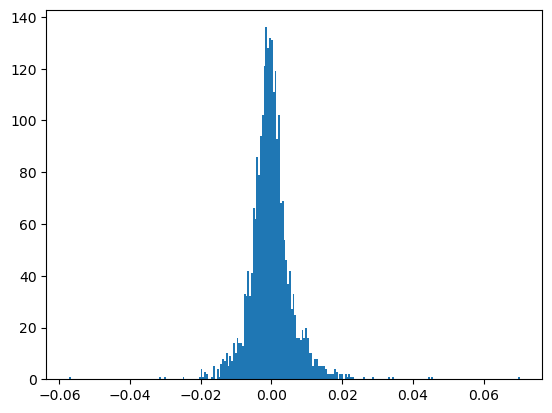

In [43]:
plt.hist(ind_loss @ weights, bins = 250)
plt.show()

In [44]:
VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, .95)

In [45]:
EWMA_HS = filtered_HS(ind_loss, weights, .95, window_size)
GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)

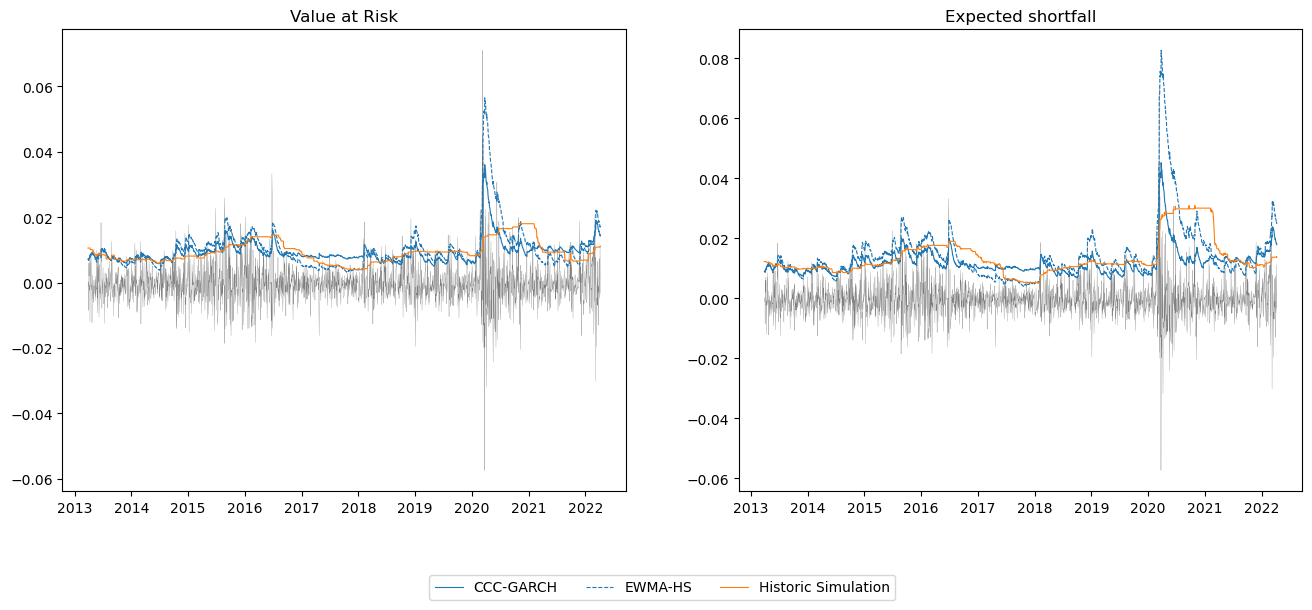

In [46]:
fig, axs = plt.subplots(1, 2, figsize = (16, 6))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[1].plot(portfolio_loss[window_size:].index, ES_GARCH[window_size:], label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[0].plot(portfolio_loss[window_size:].index, VaR_GARCH[window_size:], label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

# Replicating some graphs of the other team

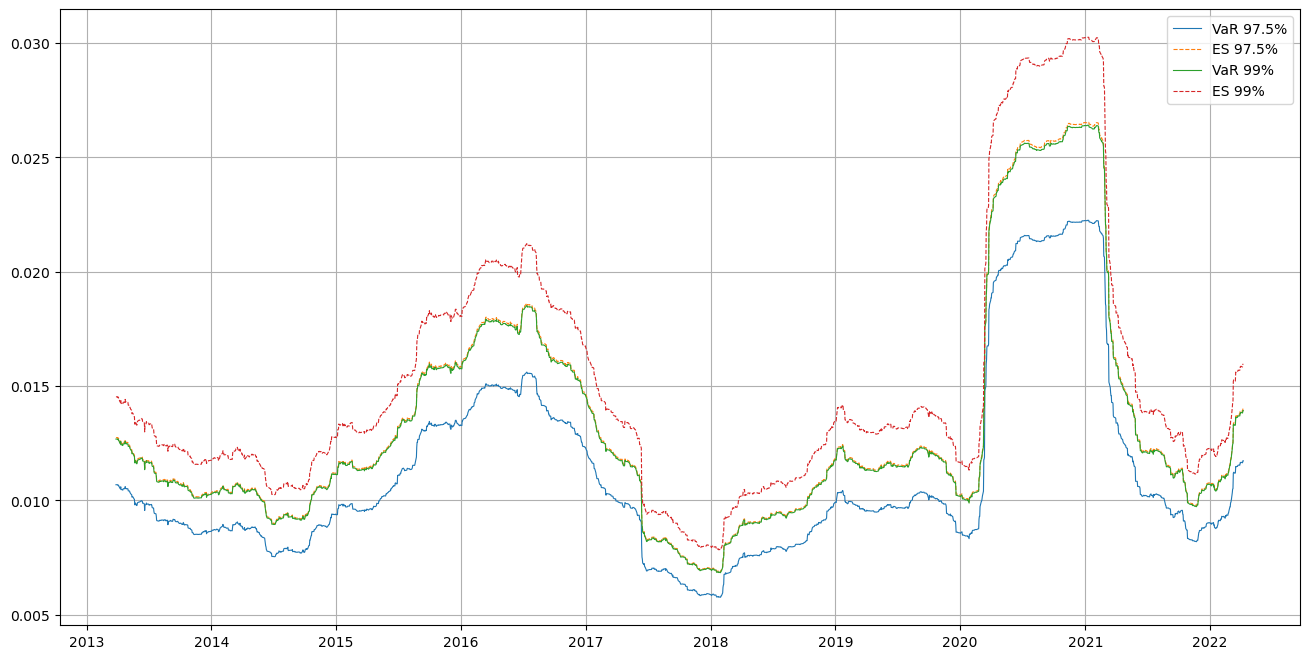

In [47]:
VaR_HS_normal_975 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .975, dist = stats.norm.ppf)
ES_HS_normal_975 = Var_Cov_ES(VaR_HS_normal_975.Vol, alpha = .975, dist = stats.norm)

VaR_HS_normal_99 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .99, dist = stats.norm.ppf)
ES_HS_normal_99 = Var_Cov_ES(VaR_HS_normal_99.Vol, alpha = .99, dist = stats.norm)

loss_df_sliced = portfolio_loss[window_size:]

plt.figure(figsize =(16, 8)) 
plt.grid(True)
plt.plot(VaR_HS_normal_975.VaR, label = 'VaR 97.5%', lw = .8)
plt.plot(ES_HS_normal_975, label = 'ES 97.5%', lw = .8, linestyle='--')

plt.plot(VaR_HS_normal_99.VaR, label = 'VaR 99%', lw = .8)
plt.plot(ES_HS_normal_99, label = 'ES 99%', lw = .8, linestyle='--')

plt.legend()
plt.savefig('VaR-Covar_comparison.pdf')
plt.show()

# BackTesting

## Obtaining Data

In [48]:
# Function to obtain interarrival Rates
def calculate_distances(array):
    
    # Get indices of 1s
    ones_indices = np.where(array == 1)[0]
    
    # Calculate distances between consecutive indices of 1s
    if len(ones_indices) > 1:
        distances = np.diff(ones_indices)
    else:
        distances = []  # If there's only one or no 1 at all, no distances to calculate
    
    return distances

def Backtest(VaR, ES, Loss, VaR_alpha, qqplot_arrival=False):
    """
    Perform a t-test to assess the accuracy of the Expected Shortfall (ES) estimation at the confidence level.

    Parameters:
    - VaR: Array of VaR estimates at the 97.5% confidence level.
    - ES: Array of ES estimates at the 97.5% confidence level.
    - Loss: Distribution of Observed Losses.

    """
    # Tests for VaR
    Violations_VaR = Loss > VaR
    print("\nVaR Violations: ", sum(Violations_VaR))

    n = len(Violations_VaR)     # Number of trials
    p = 1-VaR_alpha              # Expected probability of violation per trial
    x = sum(Violations_VaR)     # Observed number of violations
    alpha = 0.05                # Significance level for the test

    # Calculate P-values for two-tail test
    p_value_left = stats.binom.cdf(x, n, p)  # Probability of x or fewer successes
    p_value_right = 1 - stats.binom.cdf(x - 1, n, p)  # Probability of x or more successes
    p_value = min(p_value_left, p_value_right) * 2  # Two-tailed P-value

    if p_value <= alpha:
        print("VaR Violations amount differs significantly from Expected")

    if qqplot_arrival == True:
        distances = calculate_distances(Violations_VaR)
        # Checking if distances array is not empty
        if len(distances) > 0:
            # Generate a QQ-plot
            plt.figure(figsize=(12, 12))
            sm.qqplot(distances, dist=stats.expon, line="q", ax=plt.subplot(1,1,1))
            plt.title('QQ-Plot: InterArrival Distance vs. Exponential Distribution')
            plt.show()
        else:
            print("Not enough data points (1s) to generate a QQ-plot.")

    # Tests for ES
    # As an average quantity it follows normal distribution, thus we can use t test
    
    average_Real_ES = np.mean(Loss[Violations_VaR])     # Calculate Real World ES (the mean loss where VaR violation occured)
    average_Theoretical_ES = np.mean(ES[Violations_VaR])    # ES obtained with the Prediction Method
    print("\nAverage ES Real and Theoretical: ", average_Real_ES, average_Theoretical_ES)

    # Calculate the two sample z-test to find if they follow different distributions
    standard_error = np.std(Loss[Violations_VaR]) / np.sqrt(np.sum(Violations_VaR))
    # Compute the z-test statistic
    Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
    ES_p = stats.norm.sf(abs(Z_Test_ES)) * 2     # Calculate the two-sided p-value from the t-test statistic
    print("ES t-Test significance of difference: ", ES_p, " | Reject if <0.05\n\n")

    return

In [49]:
data = pd.read_excel("close_prices_portfolio.ods", engine="odf", index_col = 'Date', parse_dates = True)
start_date = '2012-01-01'
end_date = '2023-01-01'
data = data[(data.index >= pd.to_datetime(start_date)) & (data.index < pd.to_datetime(end_date))]        # Keeping only the related dates

data_log = pd.DataFrame(data.values, columns = data.columns, index = data.index)
data_log.index.name = "Date"
data_log[data_log.columns[:-1]] = np.log(data_log[data_log.columns[:-1]])
data_log['USD/EUR'] = np.exp(data_log['USD/EUR'])

weights = [.2, .2, .2, .4]
portfolio_loss, ind_loss = group4_loss_operator(log_data=data_log)

In [50]:
# Obtaining Correct windows for Year Sizes

dates = data.index
indexes_year_changes = []
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

window_size = 242                           # The only way for us to match their amount of used days in the first year is to use this strange number as window
portfolio_loss_backtest = portfolio_loss[window_size:]          # We do not need to compare these days
indexes_year_changes = np.subtract(indexes_year_changes, window_size)   # Updating indexes so that first period is not included
indexes_year_changes = np.add(indexes_year_changes, 1)                  # Updating indexes so that they can be looped
indexes_year_changes[0] = 0

Indexes where year changes:  [183, 435, 687, 939, 1191, 1442, 1693, 1945, 2198, 2450, 2517]


## VaR_975

In [51]:
alpha = .975

### Var-CoVar


Variance Covariance Normal | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  4

Average ES Real and Theoretical:  0.012672154290378794 0.01136372975399996
ES t-Test significance of difference:  0.4461427234805192  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  10

Average ES Real and Theoretical:  0.011634450164484784 0.009960662238183381
ES t-Test significance of difference:  0.015324866617387531  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  16
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.016042361497227778 0.013995200615513948
ES t-Test significance of difference:  0.05392018752175892  | Reject if <0.05



Variance Covariance Normal | VaR0.

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19280\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


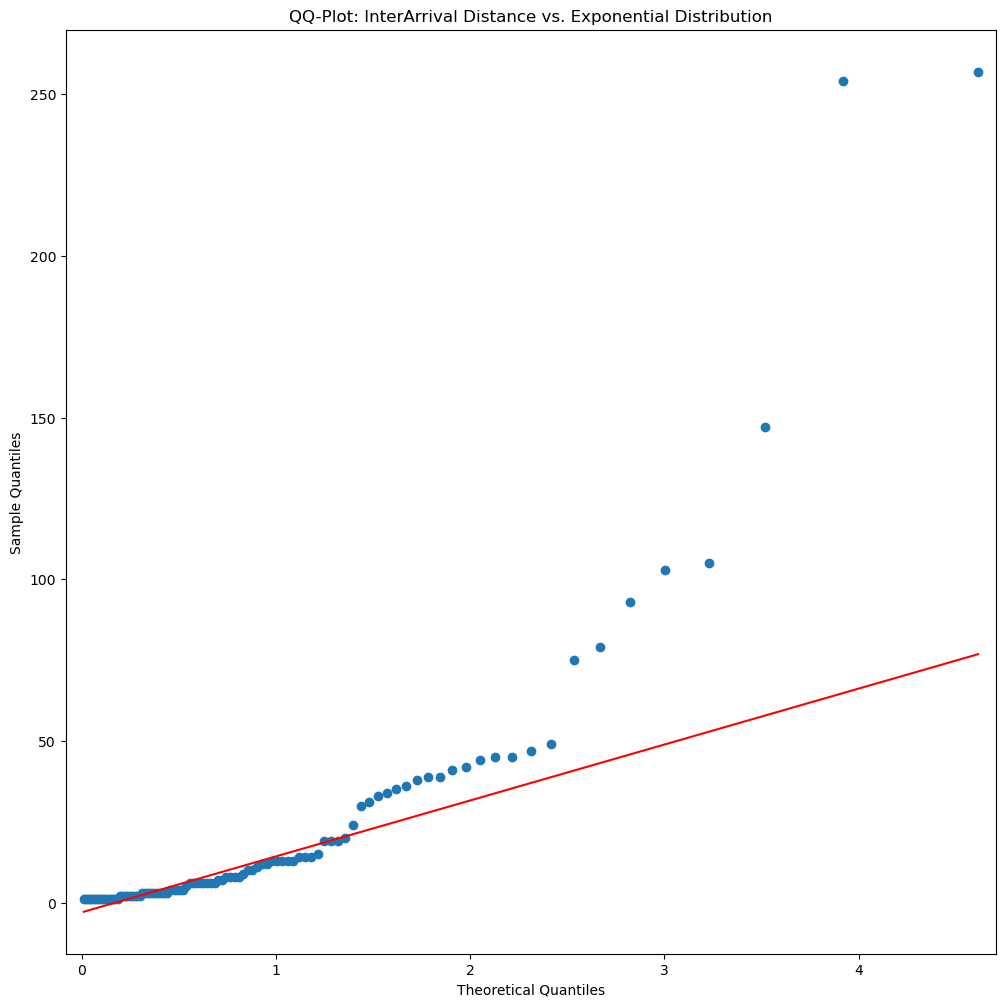


Average ES Real and Theoretical:  0.015085842591569436 0.012105444928348997
ES t-Test significance of difference:  0.0006034971433158422  | Reject if <0.05




In [52]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  4

Average ES Real and Theoretical:  0.012178210537856272 0.010041240837232984
ES t-Test significance of difference:  0.2730961085602599  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  9

Average ES Real and Theoretical:  0.01174663552327941 0.010915365251705136
ES t-Test significance of difference:  0.27270431076002954  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  11

Average ES Real and Theoretical:  0.0172431267113584 0.014550386412371304
ES t-Test significance of difference:  0.04200063448108829  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2016 | Trading Days=252
Expected number of VaR vi

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19280\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


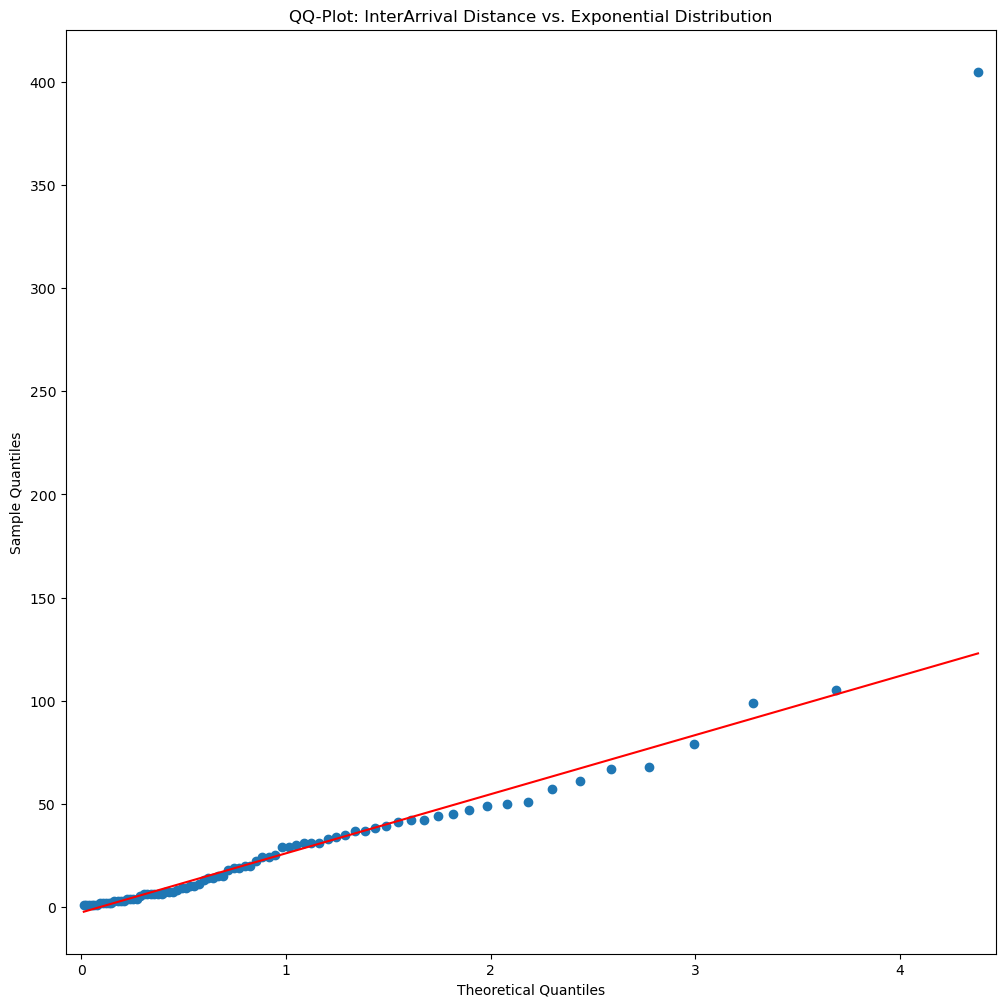


Average ES Real and Theoretical:  0.015465974933479837 0.013035723874658973
ES t-Test significance of difference:  0.01992220535308448  | Reject if <0.05




In [53]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  4

Average ES Real and Theoretical:  0.012178210537856272 0.010136085743919884
ES t-Test significance of difference:  0.29495270932704565  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  10

Average ES Real and Theoretical:  0.010519852426066265 0.010907665547213983
ES t-Test significance of difference:  0.700875994940042  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  7

Average ES Real and Theoretical:  0.019475400185793773 0.018766342518854784
ES t-Test significance of difference:  0.591152765350604  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2016 | Trading Days=252
Expected number of VaR vi

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


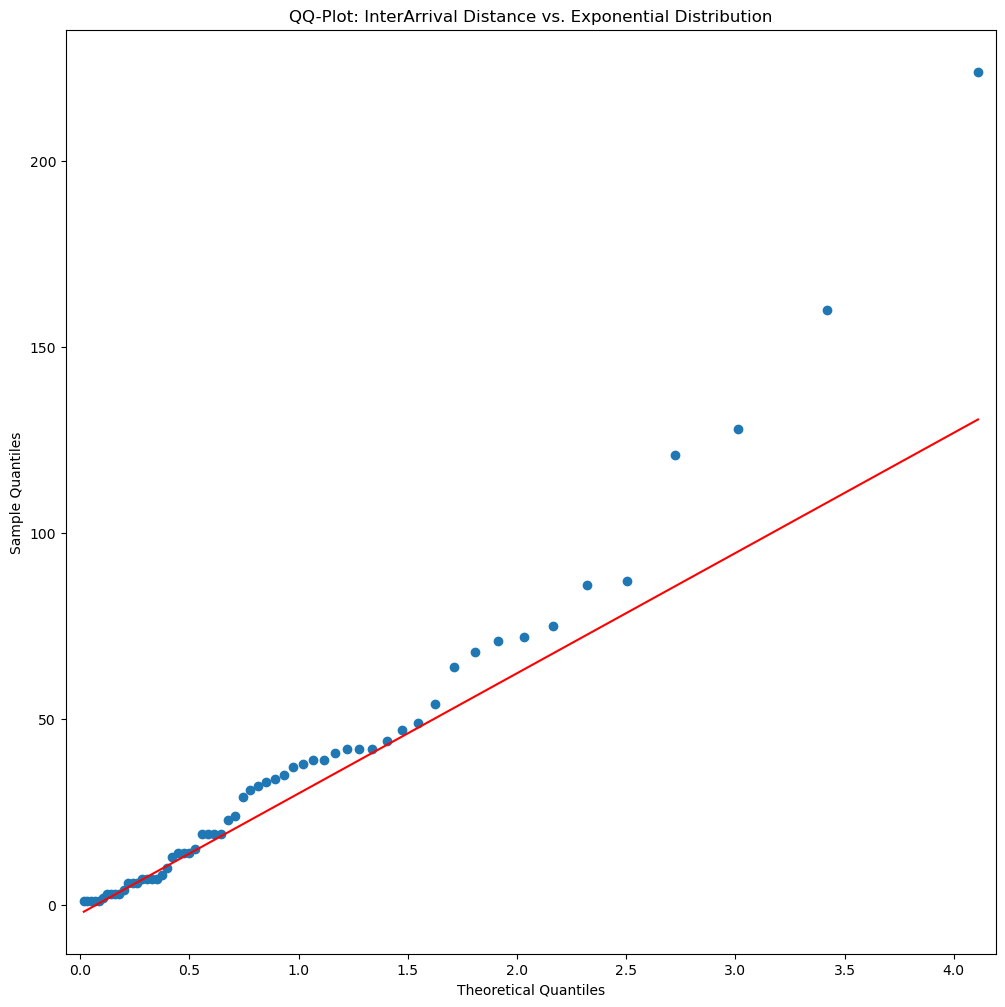


Average ES Real and Theoretical:  0.014851317638343606 0.013773956215084112
ES t-Test significance of difference:  0.39598286912504366  | Reject if <0.05




In [54]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

## VaR_99

In [55]:
alpha = .99

### Var-CoVaR


Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  2

Average ES Real and Theoretical:  0.015424715773038732 0.01257244692508926
ES t-Test significance of difference:  0.16501879512563078  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  7
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.012375787774713013 0.01121422083272518
ES t-Test significance of difference:  0.16148385897615036  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  9
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  0.019018436275759783 0.016419145725737504
ES t-Test significance of difference:  0.01352852453961207  

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


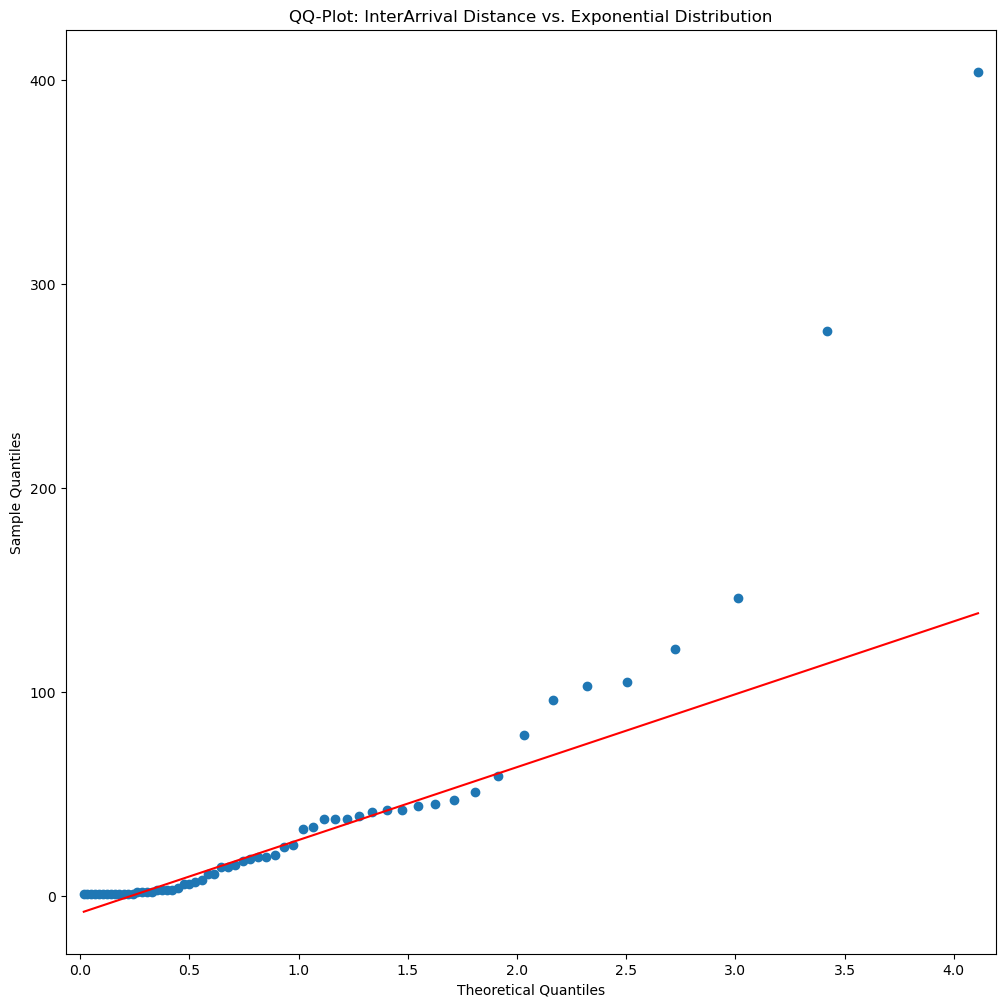


Average ES Real and Theoretical:  0.017561076756591004 0.013531155191673677
ES t-Test significance of difference:  0.001921671454985216  | Reject if <0.05




In [56]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  2

Average ES Real and Theoretical:  0.015424715773038732 0.012333812100232211
ES t-Test significance of difference:  0.13244036609003326  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  5

Average ES Real and Theoretical:  0.013075189439044533 0.012451949136134417
ES t-Test significance of difference:  0.5236299698299806  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  6

Average ES Real and Theoretical:  0.020305835888224964 0.01647443892712637
ES t-Test significance of difference:  0.0022082997360994006  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2016 | Trading Days=252
Expected number of VaR 

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19280\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


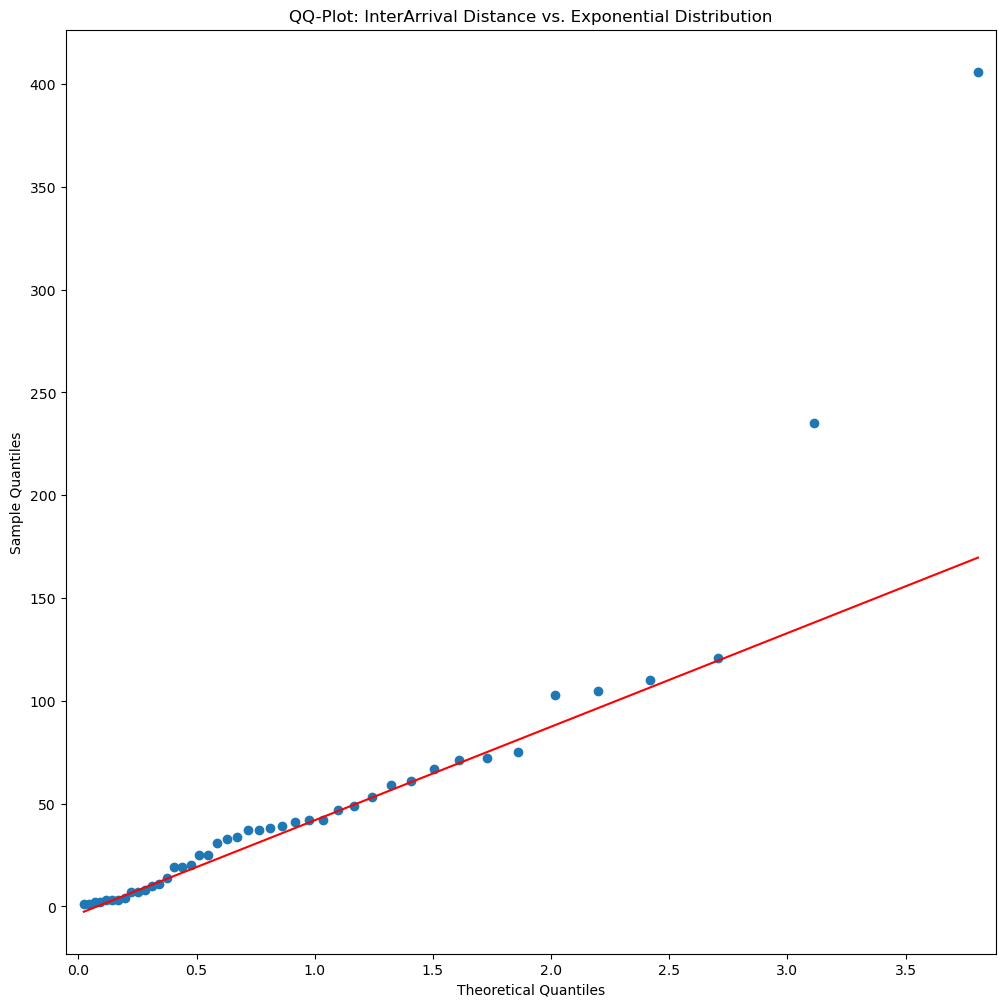


Average ES Real and Theoretical:  0.01856478441831111 0.015203738812738789
ES t-Test significance of difference:  0.04353607372865688  | Reject if <0.05




In [57]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  2

Average ES Real and Theoretical:  0.015424715773038732 0.013184463932488864
ES t-Test significance of difference:  0.2755021259234933  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  3

Average ES Real and Theoretical:  0.01348161227047584 0.013822866533400776
ES t-Test significance of difference:  0.7264199446899708  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  3

Average ES Real and Theoretical:  0.02217912317005798 0.020932423410622472
ES t-Test significance of difference:  0.5023504164586645  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2016 | Trading Days=252
Expected number of VaR viola

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_19280\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


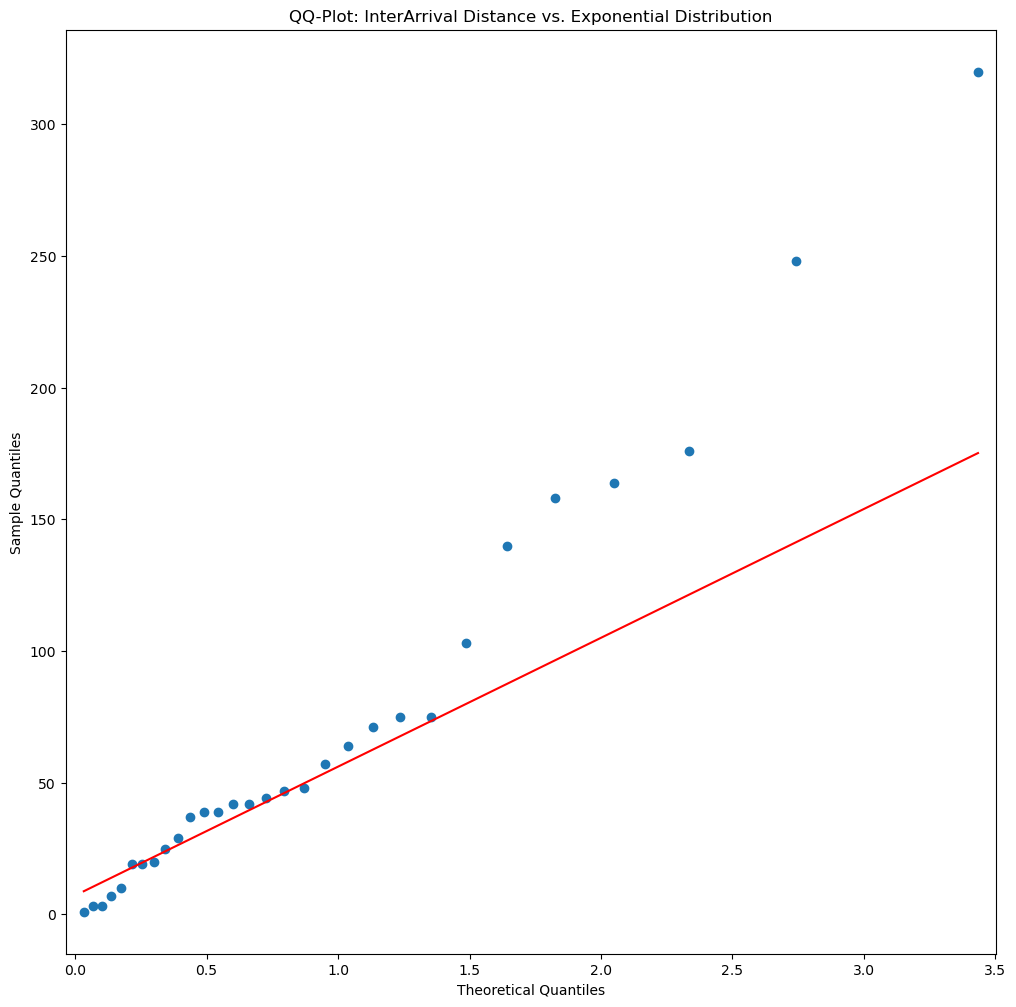


Average ES Real and Theoretical:  0.01734352782319674 0.015700661395561408
ES t-Test significance of difference:  0.4697196132555388  | Reject if <0.05




In [58]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

# Stress Test

### Changing Last Entry DAX

In [59]:
data = pd.read_excel("close_prices_portfolio.ods", engine="odf", index_col = 'Date', parse_dates = True)
data.iloc[249]["DAX"] = data.iloc[249]["DAX"]*0.8

data_log = pd.DataFrame(data.values, columns = data.columns, index = data.index)
data_log.index.name = "Date"
data_log[data_log.columns[:-1]] = np.log(data_log[data_log.columns[:-1]])
data_log['USD/EUR'] = np.exp(data_log['USD/EUR'])

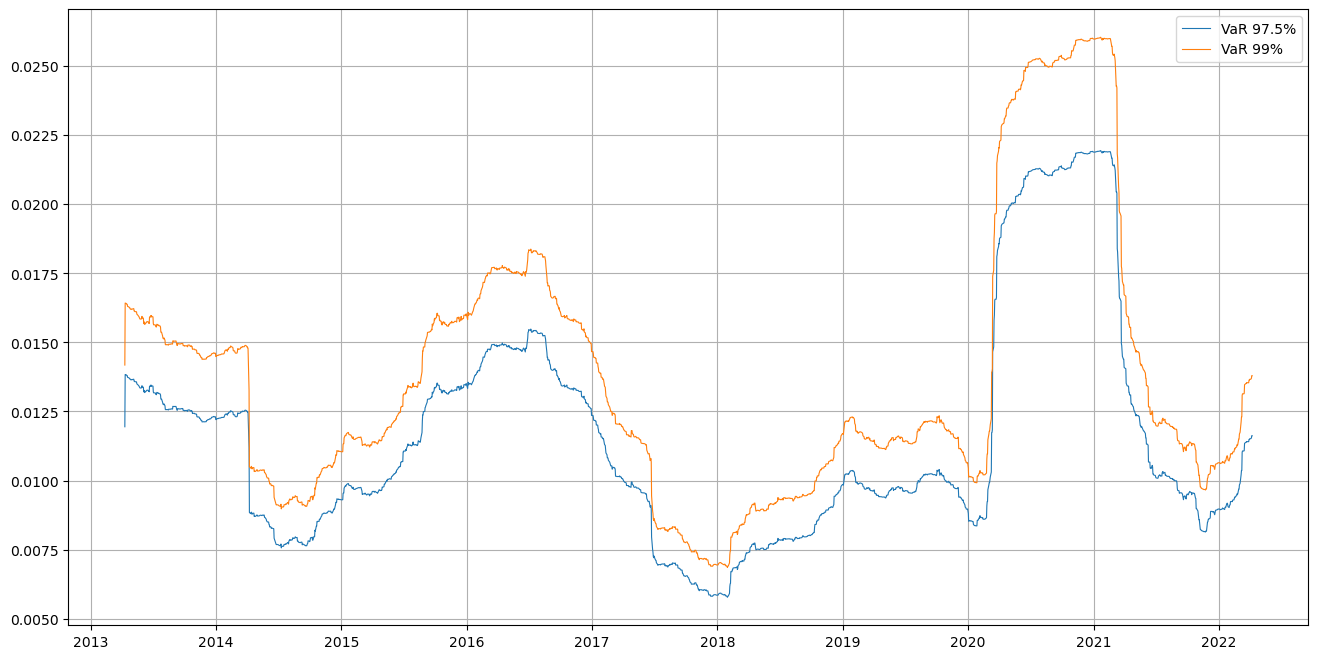

In [60]:
portfolio_loss, ind_loss = group4_loss_operator(log_data=data_log)

window_size = 250 # days
weights = [.2, .2, .2, .4]

VaR_HS_normal_975 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .975, dist = stats.norm.ppf)
ES_HS_normal_975 = Var_Cov_ES(VaR_HS_normal_975.Vol, alpha = .975, dist = stats.norm)

VaR_HS_normal_99 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .99, dist = stats.norm.ppf)
ES_HS_normal_99 = Var_Cov_ES(VaR_HS_normal_99.Vol, alpha = .99, dist = stats.norm)

loss_df_sliced = portfolio_loss[window_size:]

plt.figure(figsize =(16, 8)) 
plt.grid(True)
plt.plot(VaR_HS_normal_975.VaR, label = 'VaR 97.5%', lw = .8)
#plt.plot(ES_HS_normal_975, label = 'ES 97.5%', lw = .8, linestyle='--')

plt.plot(VaR_HS_normal_99.VaR, label = 'VaR 99%', lw = .8)
#plt.plot(ES_HS_normal_99, label = 'ES 99%', lw = .8, linestyle='--')

plt.legend()
plt.savefig('VaR-Covar_comparison.pdf')
plt.show()